Upload your Online Retail CSV file


Saving data.csv to data.csv

Dataset loaded successfully!
Original Shape: (541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  

Data Cleaning Completed!
Cleaned Shape: (392692, 9)

Missing Values:
 InvoiceNo      0
StockCode      0
Description    0
Quant

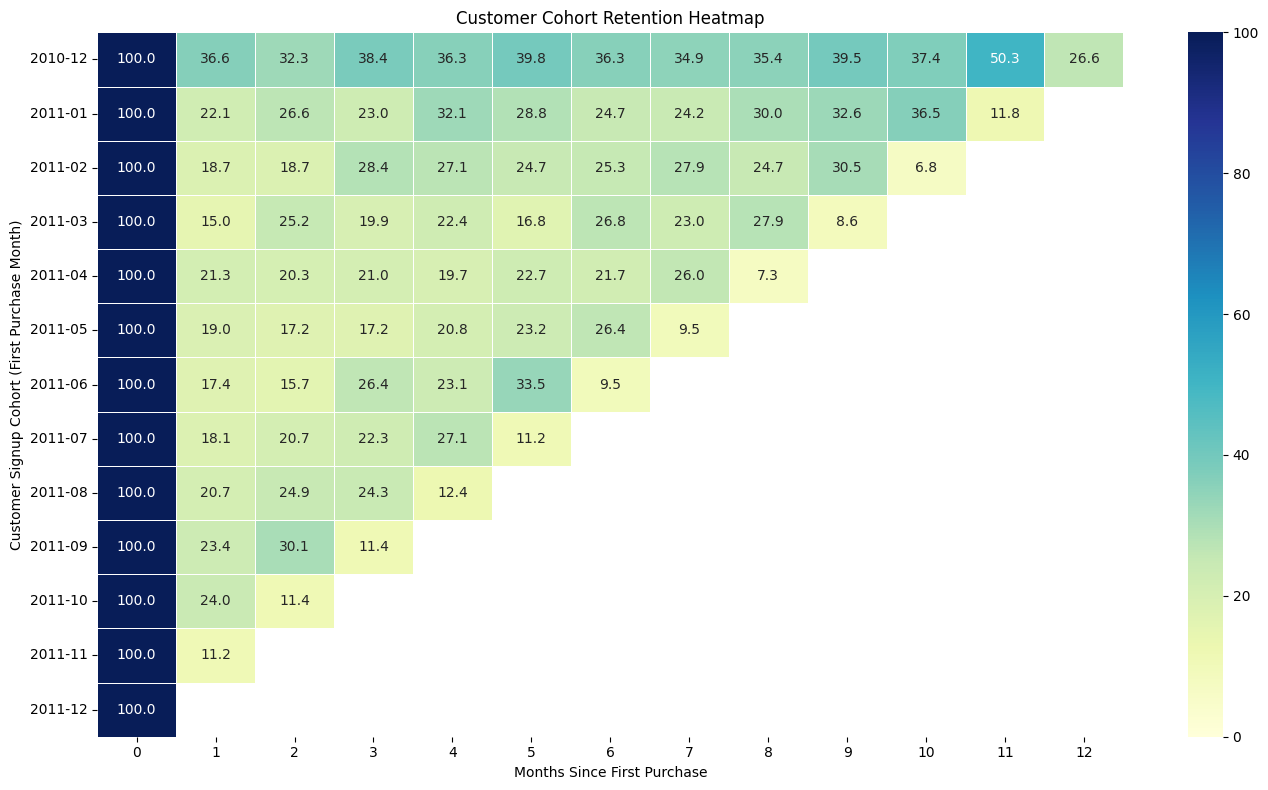


COHORT CLV REPORT
   CohortMonth  Total_Customers  Total_Cohort_Revenue  Average_CLV  \
0      2010-12              885            4502009.52      5087.02   
1      2011-01              417            1122956.98      2692.94   
2      2011-02              380             592499.86      1559.21   
3      2011-03              452             641668.76      1419.62   
4      2011-04              300             325722.91      1085.74   
5      2011-05              284             454679.43      1600.98   
6      2011-06              242             272500.43      1126.03   
7      2011-07              188             143727.89       764.51   
8      2011-08              169             195765.39      1158.38   
9      2011-09              299             232633.72       778.04   
10     2011-10              358             225683.87       630.40   
11     2011-11              323             150354.67       465.49   
12     2011-12               41              27005.46       658.67   



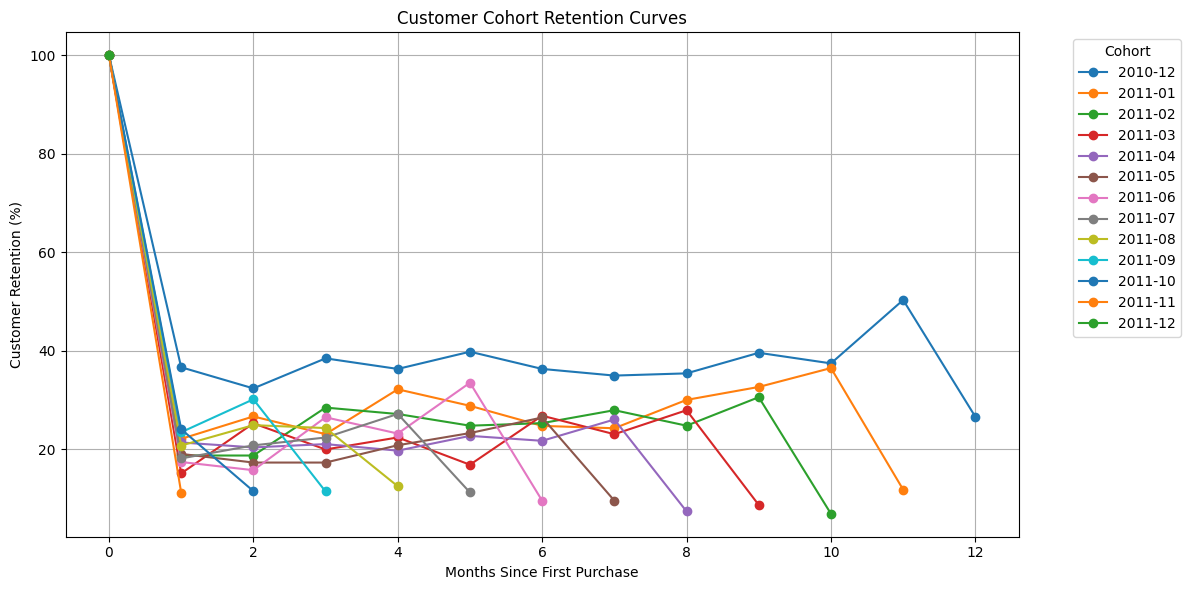

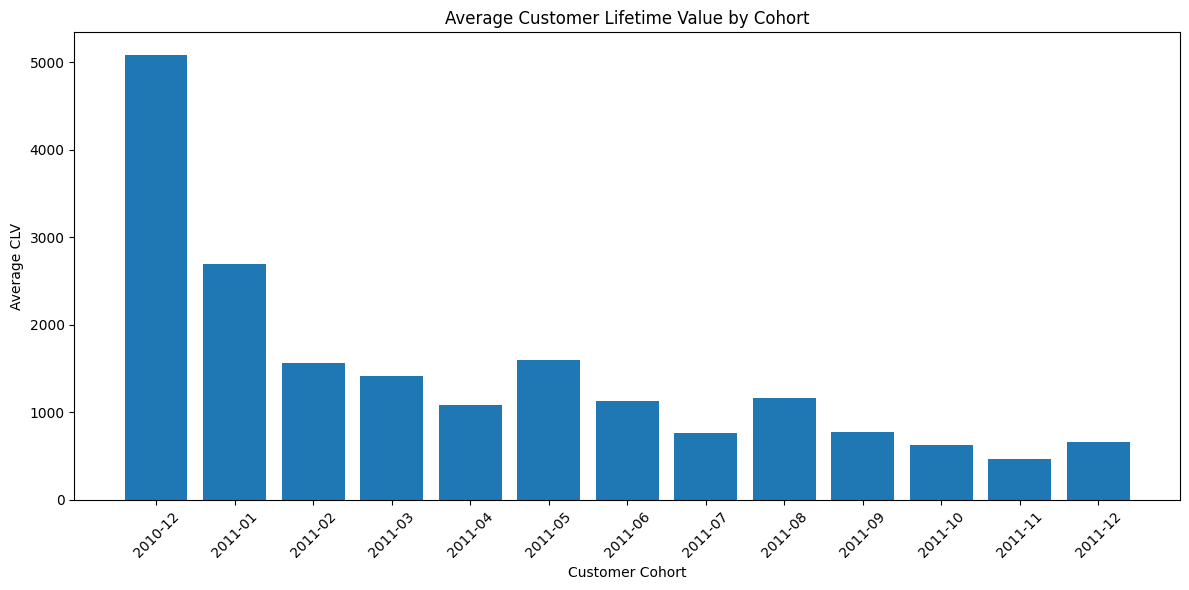


========== BUSINESS INSIGHTS ==========
Total Customers: 4338
Total Transactions: 18532
Total Revenue: 8887208.89
Overall Average CLV: 2048.69

Recommendations:
1. Focus on retaining customers from high-retention cohorts.
2. Investigate why some cohorts have lower retention.
3. Provide loyalty offers to encourage repeat purchases.
4. Focus marketing efforts on valuable customer groups.

Note:
CLV here represents historical average customer revenue
during the available dataset period, not a future prediction.

Acquisition channel analysis skipped:
The dataset does not contain an acquisition channel column.

TASK 4 ANALYSIS COMPLETED SUCCESSFULLY!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ============================================================
# TASK 4: CUSTOMER LIFETIME VALUE (CLV) & COHORT ANALYSIS
# MAVRISTA TECHNOLOGIES - DATA SCIENCE INTERNSHIP
# ============================================================

import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os
from google.colab import files

# ------------------------------------------------------------
# 1. UPLOAD DATASET
# ------------------------------------------------------------

print("Upload your Online Retail CSV file")
uploaded = files.upload()

file_name = next(iter(uploaded.keys()))

try:
    df = pd.read_csv(file_name, encoding="ISO-8859-1")
except:
    df = pd.read_csv(file_name)

print("\nDataset loaded successfully!")
print("Original Shape:", df.shape)
print(df.head())

# ------------------------------------------------------------
# 2. DATA CLEANING
# ------------------------------------------------------------

# Standardize column names
df.columns = df.columns.str.strip()

required_columns = [
    "InvoiceNo", "InvoiceDate", "Quantity",
    "UnitPrice", "CustomerID"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}. "
        f"Available columns: {list(df.columns)}"
    )

# Convert data types
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

df["Quantity"] = pd.to_numeric(
    df["Quantity"], errors="coerce"
)

df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"], errors="coerce"
)

# Remove missing and duplicate records
df = df.drop_duplicates()

df = df.dropna(
    subset=[
        "InvoiceNo", "InvoiceDate",
        "CustomerID", "Quantity", "UnitPrice"
    ]
)

# Remove cancelled invoices
df = df[
    ~df["InvoiceNo"].astype(str).str.startswith("C")
]

# Remove invalid quantities and prices
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Standardize CustomerID
df["CustomerID"] = df["CustomerID"].astype(str).str.replace(
    r"\.0$", "", regex=True
)

# Calculate revenue
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("\nData Cleaning Completed!")
print("Cleaned Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

# ------------------------------------------------------------
# 3. CREATE SQLITE DATABASE
# ------------------------------------------------------------

# Create SQLite database
conn = sqlite3.connect("Task_4_Customer_Database.db")

# Store cleaned data in SQLite
df.to_sql(
    "transactions",
    conn,
    if_exists="replace",
    index=False
)

print("\nSQLite Database Created Successfully!")

# ------------------------------------------------------------
# 4. EXTRACT DATA USING SQL
# ------------------------------------------------------------

sql_query = """
SELECT
    CustomerID,
    InvoiceNo,
    InvoiceDate,
    Quantity,
    UnitPrice,
    Revenue
FROM transactions
ORDER BY InvoiceDate;
"""

data = pd.read_sql_query(sql_query, conn)

data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])

print("\nData Extracted Using SQL!")
print(data.head())

# ------------------------------------------------------------
# 5. CUSTOMER COHORT ASSIGNMENT
# ------------------------------------------------------------

# Convert invoice date into monthly period
data["InvoiceMonth"] = data["InvoiceDate"].dt.to_period("M")

# Find each customer's first purchase month
data["CohortMonth"] = data.groupby(
    "CustomerID"
)["InvoiceMonth"].transform("min")

# Calculate cohort index
data["CohortIndex"] = (
    (data["InvoiceMonth"].dt.year -
     data["CohortMonth"].dt.year) * 12
    +
    (data["InvoiceMonth"].dt.month -
     data["CohortMonth"].dt.month)
)

print("\nCohort Assignment Completed!")
print(data[
    ["CustomerID", "InvoiceMonth",
     "CohortMonth", "CohortIndex"]
].head())

# ------------------------------------------------------------
# 6. BUILD COHORT RETENTION TABLE
# ------------------------------------------------------------

# Count unique active customers in each cohort month
cohort_data = data.groupby(
    ["CohortMonth", "CohortIndex"]
)["CustomerID"].nunique().reset_index()

cohort_counts = cohort_data.pivot(
    index="CohortMonth",
    columns="CohortIndex",
    values="CustomerID"
)

# Calculate retention percentage
cohort_sizes = cohort_counts.iloc[:, 0]

retention = cohort_counts.divide(
    cohort_sizes, axis=0
) * 100

retention = retention.round(2)

print("\nCOHORT RETENTION TABLE (%)")
print(retention)

retention.to_csv("Task_4_Cohort_Retention.csv")

# ------------------------------------------------------------
# 7. COHORT RETENTION HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(14, 8))

sns.heatmap(
    retention,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=100
)

plt.title("Customer Cohort Retention Heatmap")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Signup Cohort (First Purchase Month)")
plt.tight_layout()

plt.savefig(
    "Task_4_Cohort_Heatmap.png",
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 8. CUSTOMER LIFETIME VALUE (CLV) CALCULATION
# ------------------------------------------------------------

# Calculate total revenue per customer
customer_revenue = data.groupby(
    "CustomerID"
).agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Orders=("InvoiceNo", "nunique"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Calculate each customer's cohort month
customer_cohort = data.groupby(
    "CustomerID"
)["CohortMonth"].min().reset_index()

customer_clv = customer_revenue.merge(
    customer_cohort,
    on="CustomerID"
)

# Calculate average CLV for each cohort
clv_report = customer_clv.groupby(
    "CohortMonth"
).agg(
    Total_Customers=("CustomerID", "nunique"),
    Total_Cohort_Revenue=("Total_Revenue", "sum"),
    Average_CLV=("Total_Revenue", "mean"),
    Average_Orders=("Total_Orders", "mean")
).reset_index()

clv_report["Average_CLV"] = clv_report[
    "Average_CLV"
].round(2)

clv_report["Total_Cohort_Revenue"] = clv_report[
    "Total_Cohort_Revenue"
].round(2)

clv_report["Average_Orders"] = clv_report[
    "Average_Orders"
].round(2)

print("\nCOHORT CLV REPORT")
print(clv_report)

# Overall historical average customer revenue
overall_clv = customer_clv[
    "Total_Revenue"
].mean()

print("\nOverall Average Customer Lifetime Value:",
      round(overall_clv, 2))

clv_report.to_csv(
    "Task_4_CLV_Report.csv",
    index=False
)

customer_clv.to_csv(
    "Task_4_Customer_Level_CLV.csv",
    index=False
)

# ------------------------------------------------------------
# 9. IDENTIFY BEST AND WORST COHORTS
# ------------------------------------------------------------

# Compare cohorts using Month 1 retention
if 1 in retention.columns:
    month1_retention = retention[1].dropna()

    # Exclude cohorts with fewer than 2 customers
    eligible_cohorts = month1_retention[
        cohort_sizes.loc[month1_retention.index] >= 2
    ]

    if len(eligible_cohorts) > 0:

        best_cohort = eligible_cohorts.idxmax()
        worst_cohort = eligible_cohorts.idxmin()

        print("\nBEST PERFORMING COHORT:")
        print("Cohort:", best_cohort)
        print("Month 1 Retention:",
              eligible_cohorts.max(), "%")

        print("\nWORST PERFORMING COHORT:")
        print("Cohort:", worst_cohort)
        print("Month 1 Retention:",
              eligible_cohorts.min(), "%")

    else:
        print("\nNot enough eligible cohorts for comparison.")

else:
    print("\nMonth 1 retention data is not available.")

# ------------------------------------------------------------
# 10. COHORT RETENTION CURVE
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

for cohort in retention.index:
    plt.plot(
        retention.columns,
        retention.loc[cohort],
        marker="o",
        label=str(cohort)
    )

plt.title("Customer Cohort Retention Curves")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Retention (%)")
plt.legend(
    title="Cohort",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "Task_4_Retention_Curves.png",
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 11. CLV VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.bar(
    clv_report["CohortMonth"].astype(str),
    clv_report["Average_CLV"]
)

plt.title("Average Customer Lifetime Value by Cohort")
plt.xlabel("Customer Cohort")
plt.ylabel("Average CLV")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "Task_4_CLV_Chart.png",
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 12. BUSINESS INSIGHTS
# ------------------------------------------------------------

print("\n========== BUSINESS INSIGHTS ==========")

print("Total Customers:", data["CustomerID"].nunique())

print("Total Transactions:", data["InvoiceNo"].nunique())

print("Total Revenue:", round(data["Revenue"].sum(), 2))

print("Overall Average CLV:", round(overall_clv, 2))

print("\nRecommendations:")
print("1. Focus on retaining customers from high-retention cohorts.")
print("2. Investigate why some cohorts have lower retention.")
print("3. Provide loyalty offers to encourage repeat purchases.")
print("4. Focus marketing efforts on valuable customer groups.")

print("\nNote:")
print("CLV here represents historical average customer revenue")
print("during the available dataset period, not a future prediction.")

# Acquisition channel is not available in this dataset.
print("\nAcquisition channel analysis skipped:")
print("The dataset does not contain an acquisition channel column.")

# ------------------------------------------------------------
# 13. CLOSE SQLITE CONNECTION
# ------------------------------------------------------------

conn.close()

# ------------------------------------------------------------
# 14. SAVE ALL REPORTS INTO ZIP FILE
# ------------------------------------------------------------

output_files = [
    "Task_4_Cohort_Retention.csv",
    "Task_4_CLV_Report.csv",
    "Task_4_Customer_Level_CLV.csv",
    "Task_4_Cohort_Heatmap.png",
    "Task_4_Retention_Curves.png",
    "Task_4_CLV_Chart.png",
    "Task_4_Customer_Database.db"
]

with zipfile.ZipFile(
    "Task_4_Analysis_Reports.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for file in output_files:
        if os.path.exists(file):
            zipf.write(file)

print("\n======================================")
print("TASK 4 ANALYSIS COMPLETED SUCCESSFULLY!")
print("======================================")

# Download all reports
files.download("Task_4_Analysis_Reports.zip")
